В данной домашней работе требуется реализовать разбиение элементов выборки в вершине дерева.

$R$ - множество объектов в разбиваемой вершине, $j$ - номер признака, по которому происходит разбиение, $t$ - порог разбиения.

Критерий ошибки:

$$
Q(R, j, t) = \frac{|R_\ell|}{|R|}H(R_\ell) + \frac{|R_r|}{|R_m|}H(R_r) \to \min_{j, t}
$$

$R_\ell$ - множество объектов в левом поддереве, $R_r$ - множество объектов в правом поддереве.

$H(R)$ - критерий информативности, с помощью которого можно оценить качество распределения целевой переменной среди объектов множества $R$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from typing import Iterable, List, Tuple

from sklearn.model_selection import train_test_split

In [2]:
# Загрузим набор данных по недвижимости в Бостоне
data = pd.read_csv('boston_house_prices.csv')
data.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


**Описание набора данных:**

Boston Housing содержит данные, собранные Службой переписи населения США (англ. U.S Census Service), касающиеся недвижимости в районах Бостона. Набор данных состоит из 13 признаков и 506 строк и также предоставляет такую информацию, как уровень преступности (CRIM), ставка налога на недвижимость (TAX), возраст людей, которым принадлежит дом (AGE), соотношение числа учащихся и преподавателей в районе (PTRATIO) и другие. Данный набор данных используется для предсказания следующих целевых переменных: средняя стоимость дома (MEDV) и уровень закиси азота (NOX).

In [3]:
feature_names = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT']

X = pd.DataFrame(data, columns=feature_names, index=range(len(data)))
y = pd.DataFrame(data, columns=['MEDV'], index=range(len(data)))

X['target'] = y

In [4]:
X_train, X_test = train_test_split(X, test_size=0.25, random_state=13)

**Задание 1:** Реализуйте подсчет критерия ошибки. Для этого реализуйте функции для подсчета значения критерия информативности, а также для разбиения вершины.

In [5]:
def H(R: np.array) -> float:
    """Вычислить критерий информативности для фиксированного набора объектов R.
    Предполагается, что последний столбец содержит целевое значение
    """
    if len(R) == 0:
        return 0.0
    y = np.asarray(R)[:, -1] if not isinstance(R, pd.DataFrame) else R.iloc[:, -1].values
    return float(np.mean((y - y.mean()) ** 2))  # дисперсия


def split_node(R: np.array, feature: str, t: float) -> Iterable[np.array]:
    """
    Разделить фиксированный набор объектов R по признаку feature с пороговым значением t
    """
    R_l = R[R[feature] <= t]
    R_r = R[R[feature] > t]
    return R_l, R_r


def Q(R: np.array, feature: str, t: float) -> float:
    """
    Вычислить функционал качества для заданных параметров разделения
    """
    R_l, R_r = split_node(R, feature, t)
    return len(R_l) / len(R) * H(R_l) + len(R_r) / len(R) * H(R_r)

**Задание 2:** Переберите все возможные разбиения обучающей выборки по одному из признаков и постройте график критерия ошибки в зависимости от значения порога.

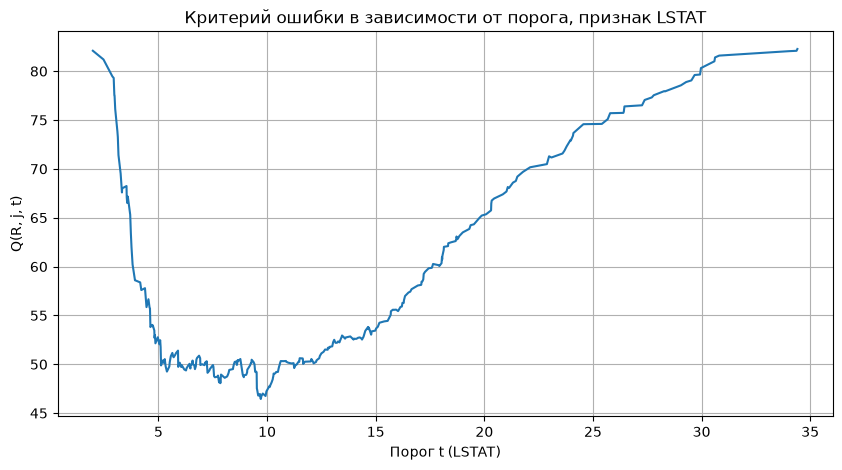

In [6]:
feature = 'LSTAT'

# все возможные пороги: уникальные значения признака, кроме максимального
# (при t = max правая часть пустая)
thresholds = np.sort(X_train[feature].unique())[:-1]
q_values = [Q(X_train, feature, t) for t in thresholds]

plt.figure(figsize=(10, 5))
plt.plot(thresholds, q_values)
plt.xlabel(f'Порог t ({feature})')
plt.ylabel('Q(R, j, t)')
plt.title(f'Критерий ошибки в зависимости от порога, признак {feature}')
plt.grid(True)
plt.show()

**Задание 3:** Напишите функцию, находящую оптимальное разбиение данной вершины по данному признаку.

In [7]:
def get_optimal_split(R: np.array, feature: str) -> Tuple[float, List[float]]:
    thresholds = np.sort(R[feature].unique())[:-1]
    q_values = [Q(R, feature, t) for t in thresholds]
    best_t = thresholds[int(np.argmin(q_values))]
    return best_t, q_values

**Задание 4:** Для первого разбиения найдите признак, показывающий наилучшее качество. Каков порог разбиения и значение качества? Постройте график критерия ошибки для данного признака в зависимости от значения порога.

RM       t =     6.7940  Q = 46.4261
LSTAT    t =     9.7100  Q = 46.4480
INDUS    t =     6.4100  Q = 60.3475
PTRATIO  t =    19.6000  Q = 63.0559
NOX      t =     0.6680  Q = 64.5617
TAX      t =   403.0000  Q = 67.3416
CRIM     t =     5.8240  Q = 67.3925
ZN       t =    12.5000  Q = 69.3408
AGE      t =    91.5000  Q = 70.8891
RAD      t =     8.0000  Q = 71.1384
DIS      t =     2.0063  Q = 71.4051
B        t =   344.9100  Q = 72.8111
CHAS     t =     0.0000  Q = 78.9400

Лучший признак: RM, порог = 6.7940, Q = 46.4261


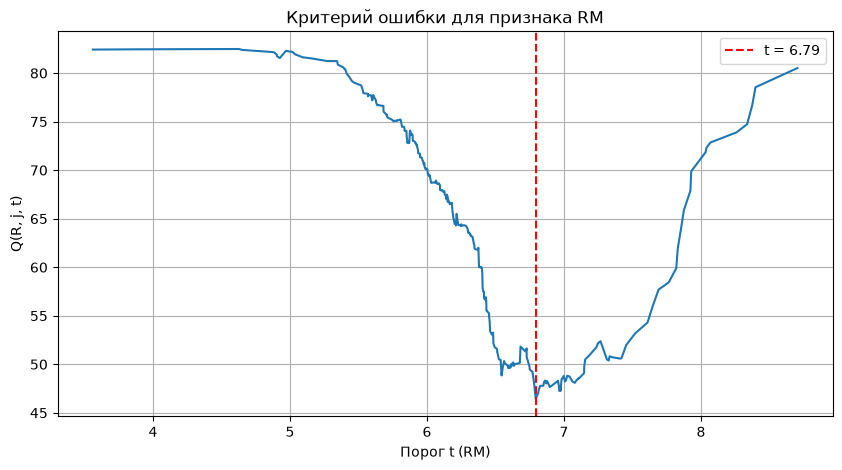

In [8]:
results = {}
for feature in feature_names:
    t_opt, q_vals = get_optimal_split(X_train, feature)
    results[feature] = (t_opt, min(q_vals))

for f, (t, q) in sorted(results.items(), key=lambda kv: kv[1][1]):
    print(f'{f:8s} t = {t:10.4f}  Q = {q:.4f}')

best_feature = min(results, key=lambda f: results[f][1])
best_t, best_q = results[best_feature]
print(f'\nЛучший признак: {best_feature}, порог = {best_t:.4f}, Q = {best_q:.4f}')

# график критерия для лучшего признака
thresholds = np.sort(X_train[best_feature].unique())[:-1]
_, q_vals = get_optimal_split(X_train, best_feature)

plt.figure(figsize=(10, 5))
plt.plot(thresholds, q_vals)
plt.axvline(best_t, color='r', linestyle='--', label=f't = {best_t:.2f}')
plt.xlabel(f'Порог t ({best_feature})')
plt.ylabel('Q(R, j, t)')
plt.title(f'Критерий ошибки для признака {best_feature}')
plt.legend()
plt.grid(True)
plt.show()

**Задание 5:** Изобразите разбиение визуально. Для этого постройте диаграмму рассеяния целевой переменной в зависимости от значения входного признака. Далее изобразите вертикальную линию, соответствующую порогу разбиения.

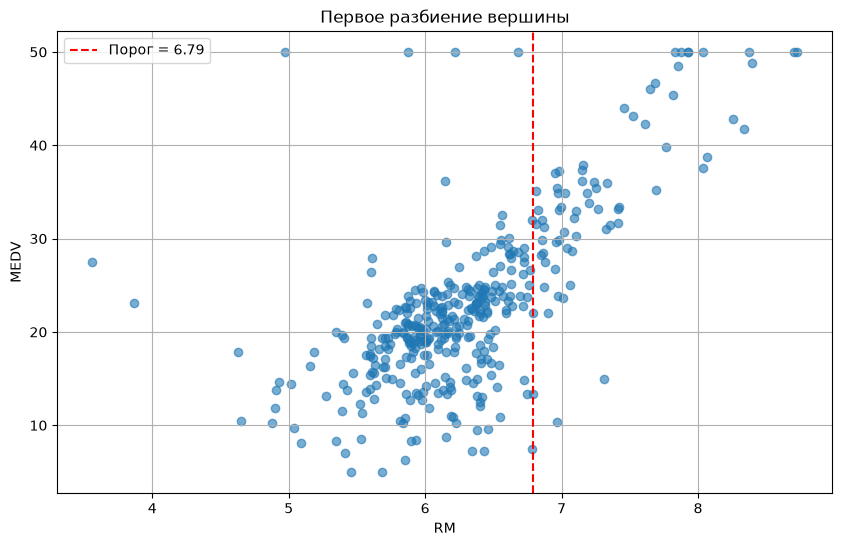

In [9]:
plt.figure(figsize=(10, 6))
plt.scatter(X_train[best_feature], X_train['target'], alpha=0.6)
plt.axvline(best_t, color='r', linestyle='--', label=f'Порог = {best_t:.2f}')
plt.xlabel(best_feature)
plt.ylabel('MEDV')
plt.title('Первое разбиение вершины')
plt.legend()
plt.grid(True)
plt.show()

**Задание 6:** Постройте модель обучения с помощью библиотеки модуля Decision Tree.

sklearn: признак = RM , порог = 6.802999973297119
наше:    признак = RM , порог = 6.794
MSE train: 6.259427463454357
MSE test:  17.071137206015447


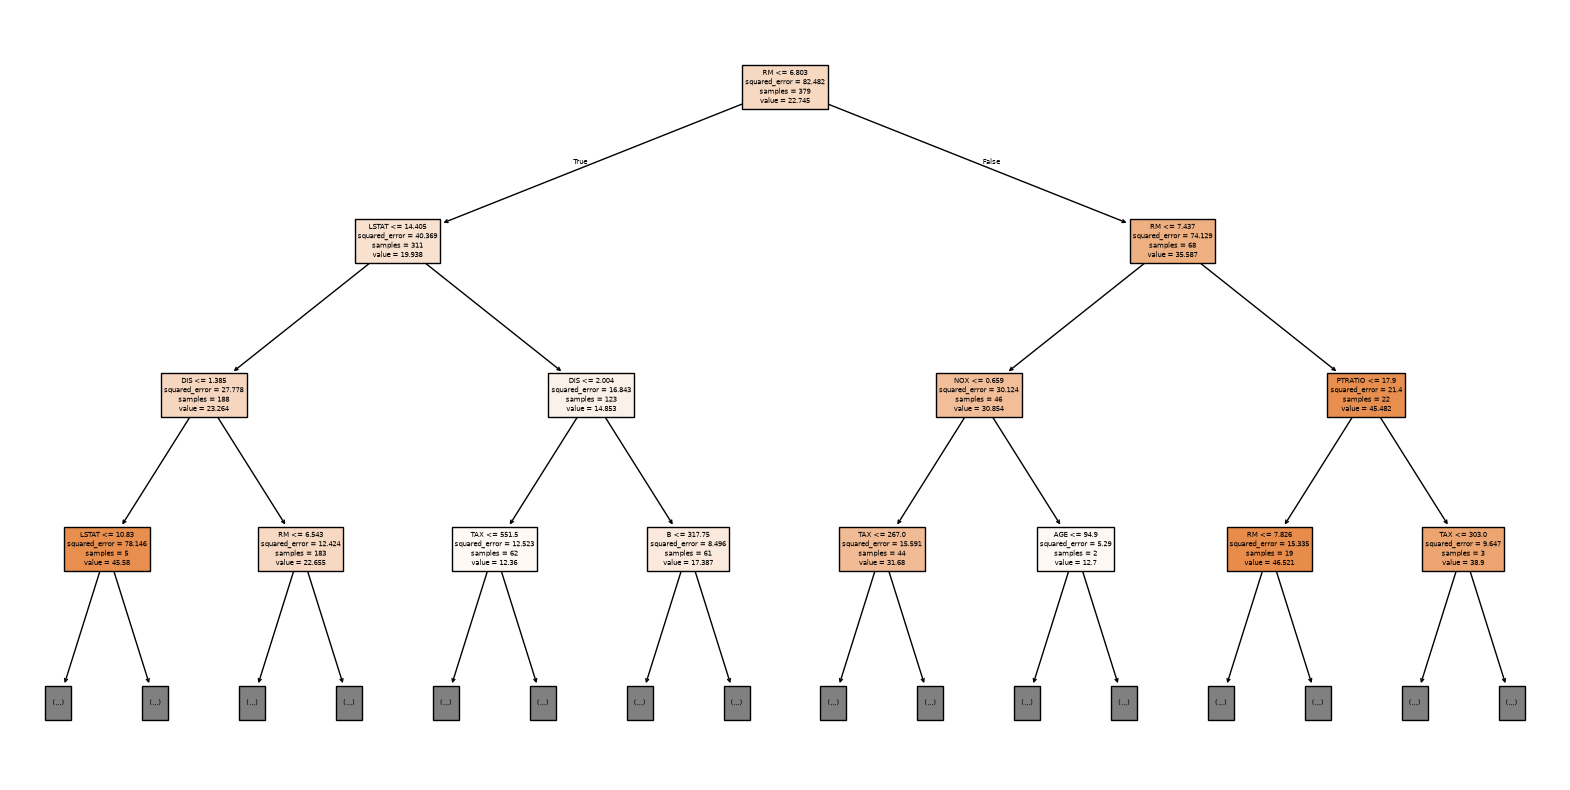

In [10]:
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_squared_error

X_tr, y_tr = X_train[feature_names], X_train['target']
X_te, y_te = X_test[feature_names], X_test['target']

# дерево глубины 1 должно воспроизвести наше первое разбиение
stump = DecisionTreeRegressor(max_depth=1, random_state=13).fit(X_tr, y_tr)
print('sklearn: признак =', feature_names[stump.tree_.feature[0]],
      ', порог =', stump.tree_.threshold[0])
print('наше:    признак =', best_feature, ', порог =', best_t)

# полноценная модель
tree = DecisionTreeRegressor(max_depth=5, random_state=13)
tree.fit(X_tr, y_tr)

print('MSE train:', mean_squared_error(y_tr, tree.predict(X_tr)))
print('MSE test: ', mean_squared_error(y_te, tree.predict(X_te)))

plt.figure(figsize=(20, 10))
plot_tree(tree, feature_names=feature_names, filled=True, max_depth=3)
plt.show()